# Risk management: time to expiry and the Greeks

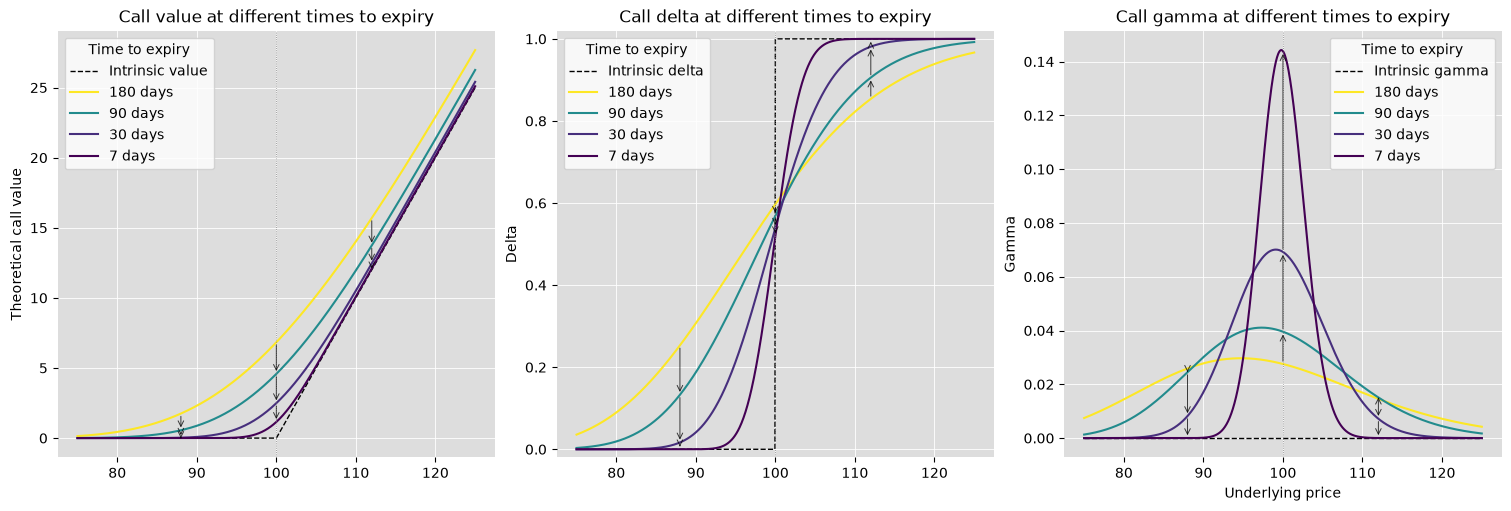

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import Normalize
from scipy.stats import norm

spot = 100
strike = 100
risk_free_rate = 0.05
volatility = 0.20
underlying_price = np.linspace(75, 125, 1001)
expiry_days = [180, 90, 30, 7]
expiry_colours = plt.get_cmap("viridis")

fig, (value_ax, delta_ax, gamma_ax) = plt.subplots(
    1, 3, sharey=False, figsize=(15, 5), layout="constrained"
)

intrinsic_value = np.maximum(underlying_price - strike, 0)
value_ax.plot(
    underlying_price,
    intrinsic_value,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Intrinsic value",
)
intrinsic_delta = (underlying_price >= strike).astype(float)
intrinsic_gamma = np.zeros_like(underlying_price)
delta_ax.plot(
    underlying_price,
    intrinsic_delta,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Intrinsic delta",
)
gamma_ax.plot(
    underlying_price,
    intrinsic_gamma,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Intrinsic gamma",
)

expiry_norm = Normalize(vmin=min(expiry_days), vmax=max(expiry_days))
for days in expiry_days:
    colour = expiry_colours(expiry_norm(days))
    tau = days / 365
    d1 = (
        np.log(underlying_price / strike) + (risk_free_rate + 0.5 * volatility**2) * tau
    ) / (volatility * np.sqrt(tau))
    d2 = d1 - volatility * np.sqrt(tau)
    call_value = underlying_price * norm.cdf(d1) - strike * np.exp(
        -risk_free_rate * tau
    ) * norm.cdf(d2)
    delta = norm.cdf(d1)
    gamma = norm.pdf(d1) / (underlying_price * volatility * np.sqrt(tau))
    label = f"{days} days"
    value_ax.plot(underlying_price, call_value, color=colour, label=label)
    delta_ax.plot(underlying_price, delta, color=colour, label=label)
    gamma_ax.plot(underlying_price, gamma, color=colour, label=label)

value_ax.set(
    title="Call value at different times to expiry", ylabel="Theoretical call value"
)
delta_ax.set(
    title="Call delta at different times to expiry", ylabel="Delta", ylim=(-0.02, 1.02)
)
gamma_ax.set(
    title="Call gamma at different times to expiry",
    xlabel="Underlying price",
    ylabel="Gamma",
)
for ax in (value_ax, delta_ax, gamma_ax):
    ax.set_facecolor("#dddddd")
    ax.set_axisbelow(True)
    ax.grid(color="white", linewidth=0.6)
    ax.axvline(strike, color="grey", linestyle=":", linewidth=0.6)
    ax.legend(title="Time to expiry")
    for spine in ax.spines.values():
        spine.set_visible(False)


# Multiple arrows show the movement from each expiry to the next shorter expiry.
def greeks_at(price, days):
    tau = days / 365
    d1 = (np.log(price / strike) + (risk_free_rate + 0.5 * volatility**2) * tau) / (
        volatility * np.sqrt(tau)
    )
    d2 = d1 - volatility * np.sqrt(tau)
    value = price * norm.cdf(d1) - strike * np.exp(-risk_free_rate * tau) * norm.cdf(d2)
    return value, norm.cdf(d1), norm.pdf(d1) / (price * volatility * np.sqrt(tau))


for price in (88, 100, 112):
    for start, end in zip(expiry_days[:-1], expiry_days[1:]):
        y_start = greeks_at(price, start)
        y_end = greeks_at(price, end)
        for ax, start_value, end_value in zip(
            (value_ax, delta_ax, gamma_ax), y_start, y_end
        ):
            ax.annotate(
                "",
                xy=(price, end_value),
                xytext=(price, start_value),
                arrowprops={
                    "arrowstyle": "->",
                    "color": "black",
                    "lw": 0.7,
                    "alpha": 0.75,
                },
            )

plt.show()

Increasing volatility and increasing time to expiry generally cause changes in the same direction, although at different scales. The log asset price at expiration is normally distributed with variance $\sigma^2 T$, so both a higher volatility $\sigma$ and a longer time to expiry $T$ increase the dispersion of possible outcomes.

Even with a fixed underlying, delta is sensitive to volatility and time. Remember that delta is approximately the probability and option expires in the money. For options ATM the delta is already ~50 and this doesn't change with greater or lesser volatility as price movements are roughly symmetric. For options very ITM/OTM if the volatility is low the option is very likely to expiry ITM/OTM, as the volatility increases the option tends to 50% likely to expire ITM/OTM.

Time passing has a similar effect (log returns have a volatility sigma^2 T). Increasing time to expiry generally moves the delta to 50, and therefore does little to change the delta ATM which is already 50. 

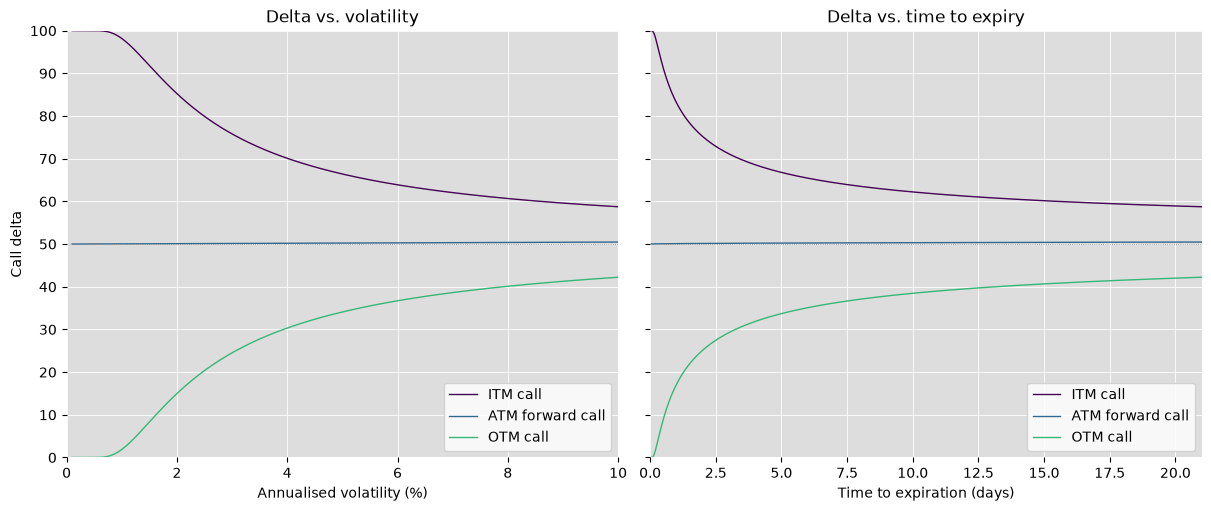

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

# Zero rates and dividends keep the forward equal to the fixed spot price.
spot = forward = 100
strikes = [99.5, 100, 100.5]
labels = ["ITM call", "ATM forward call", "OTM call"]
colors = ["#440154", "#31688e", "#35b779"]
# Small total volatility keeps forward ATM delta within 0.5 points of 50.
# Nearby strikes preserve visible ITM and OTM sensitivity.
volatilities = np.linspace(0.001, 0.10, 401)
expiry_days = np.linspace(0.05, 21, 401)
fixed_days = 21
fixed_volatility = 0.10


def call_delta(strike, sigma, tau):
    """Black-Scholes spot delta, expressed on a 0 to 100 scale (r = q = 0)."""
    d1 = (np.log(forward / strike) + 0.5 * sigma**2 * tau) / (sigma * np.sqrt(tau))
    return 100 * norm.cdf(d1)


fig, axes = plt.subplots(1, 2, sharey=True, figsize=(12, 5), layout="constrained")
vol_ax, time_ax = axes
for strike, label, color in zip(strikes, labels, colors):
    vol_ax.plot(
        100 * volatilities,
        call_delta(strike, volatilities, fixed_days / 365),
        label=label,
        color=color,
        linewidth=1,
    )
    time_ax.plot(
        expiry_days,
        call_delta(strike, fixed_volatility, expiry_days / 365),
        label=label,
        color=color,
        linewidth=1,
    )

vol_ax.set(
    title="Delta vs. volatility",
    xlabel="Annualised volatility (%)",
    ylabel="Call delta",
    xlim=(0, 10),
)
time_ax.set(
    title="Delta vs. time to expiry",
    xlabel="Time to expiration (days)",
    xlim=(0, 21),
)
for ax in axes:
    ax.set(ylim=(0, 100), yticks=np.arange(0, 101, 10))
    ax.set_facecolor("#dddddd")
    ax.set_axisbelow(True)
    ax.grid(color="white", linewidth=0.6)
    ax.axhline(50, color="grey", linestyle=":", linewidth=0.6)
    ax.legend(loc="lower right")
    for spine in ax.spines.values():
        spine.set_visible(False)
plt.show()

As delta can change even if the underlying doesn't move (such as time passing or changes in implied volatility), evidently implied volatility is a necessary factor to calculating the delta of an option position. Traders can use the implied volatility to calculate an implied delta, but this is only one way this can be done.

The sensitivity of delta to a change in implied vol is the options vanna, the sensitivity of delta to the passage of time is its charm. 

### Vanna

Vanna is the partial derivative of delta w.r.t. volatility.

Logically, deltas close to 0, 50 or 100 do not change much as volatility changes. Those ITM/OTM are likely to stay ITM/OTM as volatility changes those ATM are likely to stay around 50% likely to expire ITM. If the volatility is greater, the deltas are greater across the board which means the vanna, sensitivity of delta to volatility is lesser. If the volatility is low, any increase has a greater effect on the delta OTM/ITM. So the vanna is more pronounced when the volatility is low.

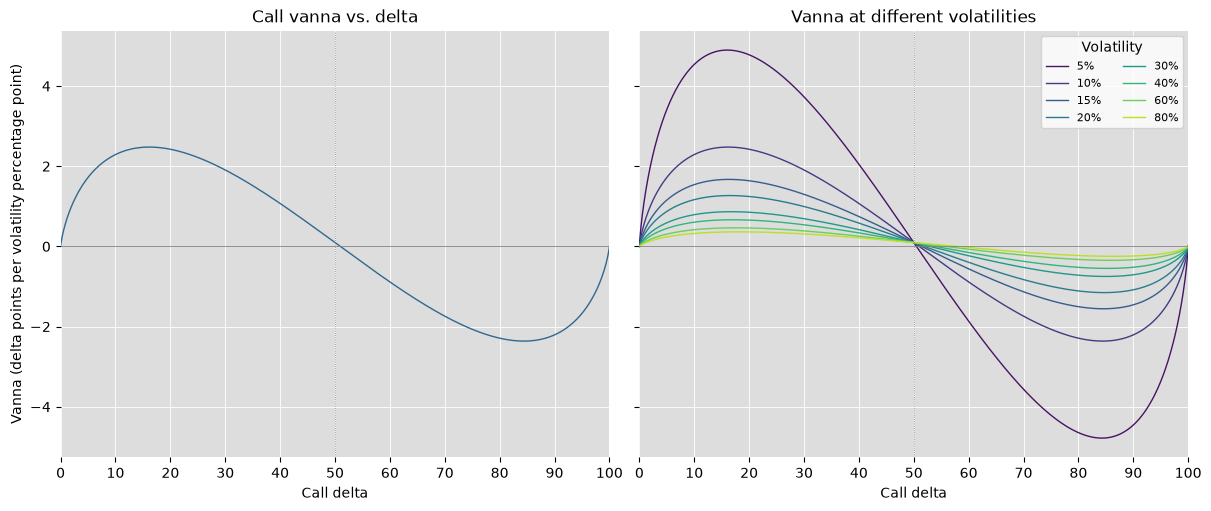

In [3]:
# Hold volatility and time fixed across the curve; vary call moneyness.
# At each point, vanna differentiates delta with spot, strike and time fixed.
vanna_volatility = 0.10
vanna_tau = 21 / 365
call_deltas = np.linspace(0.000001, 0.999999, 2001)
vanna_d1 = norm.ppf(call_deltas)
vanna_d2 = vanna_d1 - vanna_volatility * np.sqrt(vanna_tau)

# dDelta/dsigma = -phi(d1) * d2 / sigma, with zero dividends.
# Converting delta to points (x100) and volatility to percentage points
# (x0.01) cancels, so the numerical value is unchanged.
call_vanna = -norm.pdf(vanna_d1) * vanna_d2 / vanna_volatility

vanna_fig, (vanna_ax, vol_vanna_ax) = plt.subplots(
    1, 2, sharex=True, sharey=True, figsize=(12, 5), layout="constrained"
)
delta_points = np.r_[0, 100 * call_deltas, 100]
vanna_ax.plot(
    delta_points,
    np.r_[0, call_vanna, 0],
    color="#31688e",
    linewidth=1,
)
vanna_ax.set(
    title="Call vanna vs. delta",
    ylabel="Vanna (delta points per volatility percentage point)",
)

vanna_volatilities = np.array([0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.60, 0.80])
vanna_colors = plt.get_cmap("viridis")(np.linspace(0.05, 0.9, len(vanna_volatilities)))
for sigma, color in zip(vanna_volatilities, vanna_colors):
    d2 = vanna_d1 - sigma * np.sqrt(vanna_tau)
    vanna_values = -norm.pdf(vanna_d1) * d2 / sigma
    vol_vanna_ax.plot(
        delta_points,
        np.r_[0, vanna_values, 0],
        color=color,
        linewidth=1,
        label=f"{sigma:.0%}",
    )
vol_vanna_ax.set_title("Vanna at different volatilities")
vol_vanna_ax.legend(title="Volatility", ncol=2, fontsize=8, loc="upper right")

for ax in (vanna_ax, vol_vanna_ax):
    ax.set(xlabel="Call delta", xlim=(0, 100), xticks=np.arange(0, 101, 10))
    ax.set_facecolor("#dddddd")
    ax.set_axisbelow(True)
    ax.grid(color="white", linewidth=0.6)
    ax.axhline(0, color="grey", linewidth=0.6)
    ax.axvline(50, color="grey", linestyle=":", linewidth=0.6)
    for spine in ax.spines.values():
        spine.set_visible(False)
plt.show()

### Charm

The same logic applies to time to expiry, an option position further from expiry has greater deltas ITM/OTM, closer to expiry the deltas become more concentrated around the strike. Similarly to Vanna, when time to expiry is great, deltas are smoother over the strikes, closer to expiry delta becomes concentrated around the strikes so Charm becomes greater.

Charm is the partial derivative of delta w.r.t volatility. 

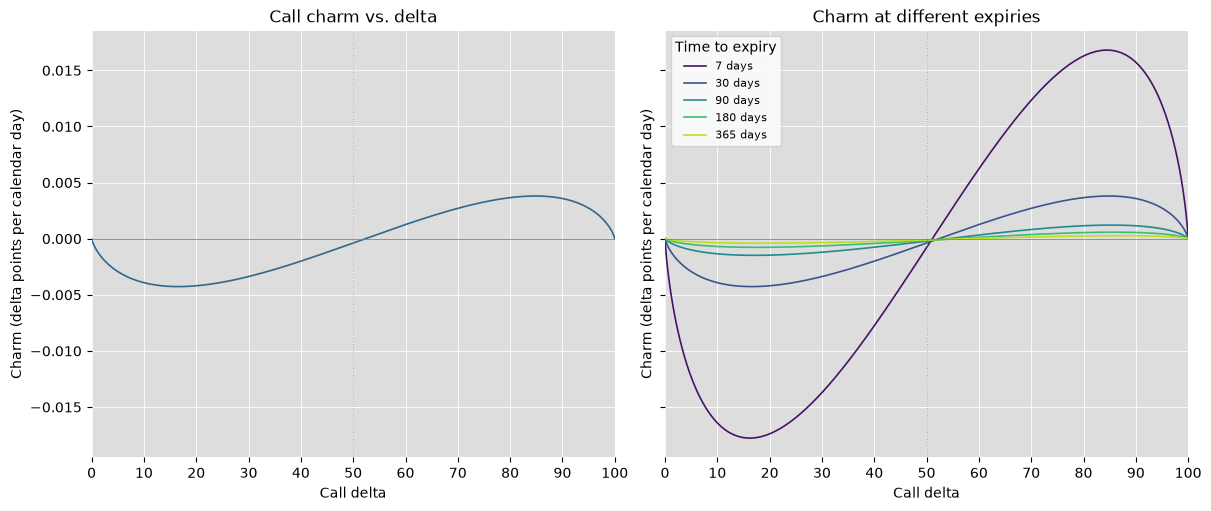

In [4]:
# Charm is the calendar-time change in delta at fixed spot, strike and volatility.
# For a call with zero rates and dividends, d/dt = -d/dT.
charm_sigma = 0.20
charm_tau = 30 / 365
charm_deltas = np.linspace(0.000001, 0.999999, 2001)
charm_d1 = norm.ppf(charm_deltas)
charm_points = np.r_[0, 100 * charm_deltas, 100]


# dDelta/dt, quoted as delta points per calendar day.
def call_charm(delta_d1, tau, sigma):
    return (
        norm.pdf(delta_d1) * (delta_d1 / (2 * tau) - sigma / (2 * np.sqrt(tau))) / 365
    )


charm_fig, (charm_ax, expiry_charm_ax) = plt.subplots(
    1, 2, sharex=True, sharey=True, figsize=(12, 5), layout="constrained"
)
charm_ax.plot(
    charm_points,
    np.r_[0, call_charm(charm_d1, charm_tau, charm_sigma), 0],
    color="#31688e",
    linewidth=1.2,
)
charm_ax.set_title("Call charm vs. delta")

charm_expiries = np.array([7, 30, 90, 180, 365])
charm_colours = plt.get_cmap("viridis")(np.linspace(0.05, 0.9, len(charm_expiries)))
for days, colour in zip(charm_expiries, charm_colours):
    values = call_charm(charm_d1, days / 365, charm_sigma)
    expiry_charm_ax.plot(
        charm_points,
        np.r_[0, values, 0],
        color=colour,
        linewidth=1.2,
        label=f"{days} days",
    )
expiry_charm_ax.set_title("Charm at different expiries")
expiry_charm_ax.legend(title="Time to expiry", fontsize=8)

for ax in (charm_ax, expiry_charm_ax):
    ax.set(
        xlabel="Call delta",
        ylabel="Charm (delta points per calendar day)",
        xlim=(0, 100),
        xticks=np.arange(0, 101, 10),
    )
    ax.set_facecolor("#dddddd")
    ax.set_axisbelow(True)
    ax.grid(color="white", linewidth=0.6)
    ax.axhline(0, color="grey", linewidth=0.6)
    ax.axvline(50, color="grey", linestyle=":", linewidth=0.6)
    for spine in ax.spines.values():
        spine.set_visible(False)
plt.show()

## Theta

Theta measures how an option's value changes as calendar time passes. An option's value is comprised of its intrinsic and extrinsic value, as time passes the extrinsic value decays and the value approaches the moneyness. Theta measures the rate of decay of an option's value as time passes. Theta is greatest at the money, for options very ITM/OTM most of the value of the option is in the intrinsic value, at the money a great amount of the option's value is in its extrinsic value.

If an underlying price and strike is 10x greater than that of another asset and contract, all other factors kept the same, then the theta is 10x greater, simply the position is more leveraged. This is represented by a straight line between the peaks of the three contracts below.

The underlying price varies along the x-axis; the three curves hold the expiry and volatility fixed while changing the strike price.

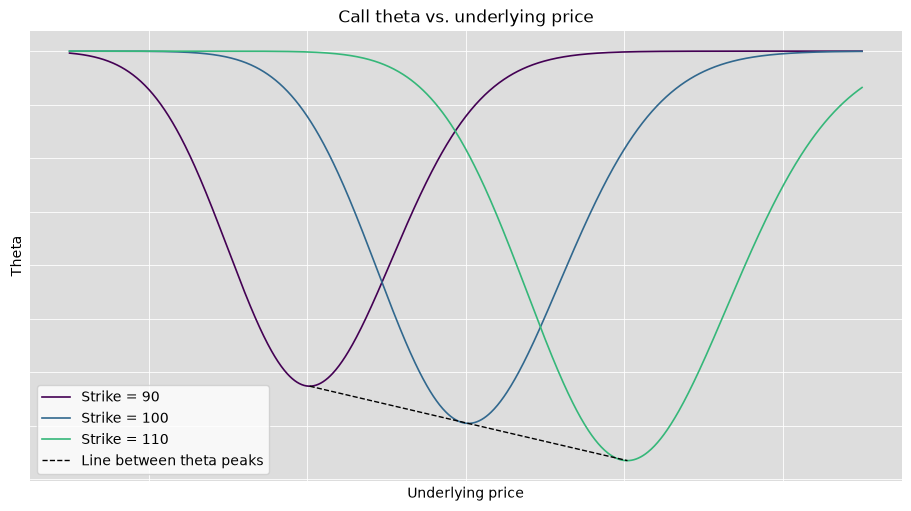

In [5]:
# Compare theta across underlying prices for three fixed-strike calls.
theta_spots = np.linspace(75, 125, 1001)
theta_strikes = [90, 100, 110]
theta_labels = ["Strike = 90", "Strike = 100", "Strike = 110"]
theta_colours = ["#440154", "#31688e", "#35b779"]
theta_sigma = 0.20
theta_tau = 30 / 365

theta_fig, theta_ax = plt.subplots(figsize=(9, 5), layout="constrained")
theta_peaks = []
for strike, label, colour in zip(theta_strikes, theta_labels, theta_colours):
    d1 = (np.log(theta_spots / strike) + 0.5 * theta_sigma**2 * theta_tau) / (
        theta_sigma * np.sqrt(theta_tau)
    )
    theta_values = -theta_spots * norm.pdf(d1) * theta_sigma / (2 * np.sqrt(theta_tau))
    theta_ax.plot(theta_spots, theta_values, color=colour, linewidth=1.2, label=label)
    peak_index = np.argmin(theta_values)
    theta_peaks.append((theta_spots[peak_index], theta_values[peak_index]))

theta_peaks.sort()
theta_ax.plot(
    [point[0] for point in theta_peaks],
    [point[1] for point in theta_peaks],
    color="black",
    linestyle="--",
    linewidth=1,
    label="Line between theta peaks",
)

theta_ax.set(
    title="Call theta vs. underlying price", xlabel="Underlying price", ylabel="Theta"
)
theta_ax.set_facecolor("#dddddd")
theta_ax.set_axisbelow(True)
theta_ax.grid(color="white", linewidth=0.6)
theta_ax.tick_params(axis="both", length=0, labelbottom=False, labelleft=False)
theta_ax.legend()
for spine in theta_ax.spines.values():
    spine.set_visible(False)
plt.show()

As an option approaches expiry, theta becomes most negative near the strike because the remaining time value is lost fastest there. For an underlying well below or above the strike, the option is already likely to expire out of the money or in the money, so the extrinsic value is already close to zero and theta tends towards zero.

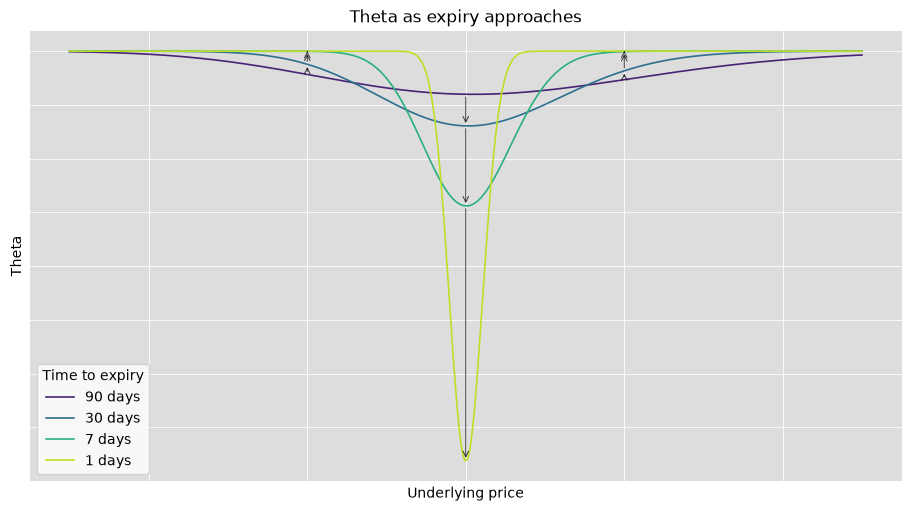

In [6]:
theta_time_spots = np.linspace(75, 125, 1001)
theta_time_strike = 100
theta_time_sigma = 0.20
theta_time_expiries = [90, 30, 7, 1]
theta_time_colours = plt.get_cmap("viridis")(
    np.linspace(0.1, 0.9, len(theta_time_expiries))
)

theta_time_fig, theta_time_ax = plt.subplots(figsize=(9, 5), layout="constrained")
for days, colour in zip(theta_time_expiries, theta_time_colours):
    tau = days / 365
    d1 = (
        np.log(theta_time_spots / theta_time_strike) + 0.5 * theta_time_sigma**2 * tau
    ) / (theta_time_sigma * np.sqrt(tau))
    theta_values = (
        -theta_time_spots * norm.pdf(d1) * theta_time_sigma / (2 * np.sqrt(tau))
    )
    theta_time_ax.plot(
        theta_time_spots,
        theta_values,
        color=colour,
        linewidth=1.2,
        label=f"{days} days",
    )

theta_time_ax.set(
    title="Theta as expiry approaches", xlabel="Underlying price", ylabel="Theta"
)
theta_time_ax.set_facecolor("#dddddd")
theta_time_ax.set_axisbelow(True)
theta_time_ax.grid(color="white", linewidth=0.6)
theta_time_ax.tick_params(axis="both", length=0, labelbottom=False, labelleft=False)
theta_time_ax.legend(title="Time to expiry")
for spine in theta_time_ax.spines.values():
    spine.set_visible(False)

# Arrows show the movement from each longer expiry to the next shorter expiry.
for price in (90, 100, 110):
    for start, end in zip(theta_time_expiries[:-1], theta_time_expiries[1:]):

        def theta_at(days):
            tau = days / 365
            d1 = (
                np.log(price / theta_time_strike) + 0.5 * theta_time_sigma**2 * tau
            ) / (theta_time_sigma * np.sqrt(tau))
            return -price * norm.pdf(d1) * theta_time_sigma / (2 * np.sqrt(tau))

        theta_time_ax.annotate(
            "",
            xy=(price, theta_at(end)),
            xytext=(price, theta_at(start)),
            arrowprops={"arrowstyle": "->", "color": "black", "lw": 0.7, "alpha": 0.75},
        )
plt.show()


Theta represents the time value of an option, for very ITM/OTM options there is little time value. For ATM options the time value is greatest (difference between EV of an option and intrinsic value). Toward expiry the theta tends to -infinty ATM and zero ITM/OTM. 

Theta is also a function of the underlying price, greater underlying prices mean theta is greater ATM as there is more time value on more sizable positions. For ITM/OTM we can see they decrease at the same rate, with ITM flattening close to expiry. With theoretical value = intrinsic + time value, we see that the time value decreases similar for ITM/OTM but intinsic is +ve for ITM and zero for OTM calls. 

ATM the theoretical value is all time value and this decreases sharply close to expiry. We see this great derivative reflected in the plot of theta as expiry approaches for ITM/ATM and OTM calls.

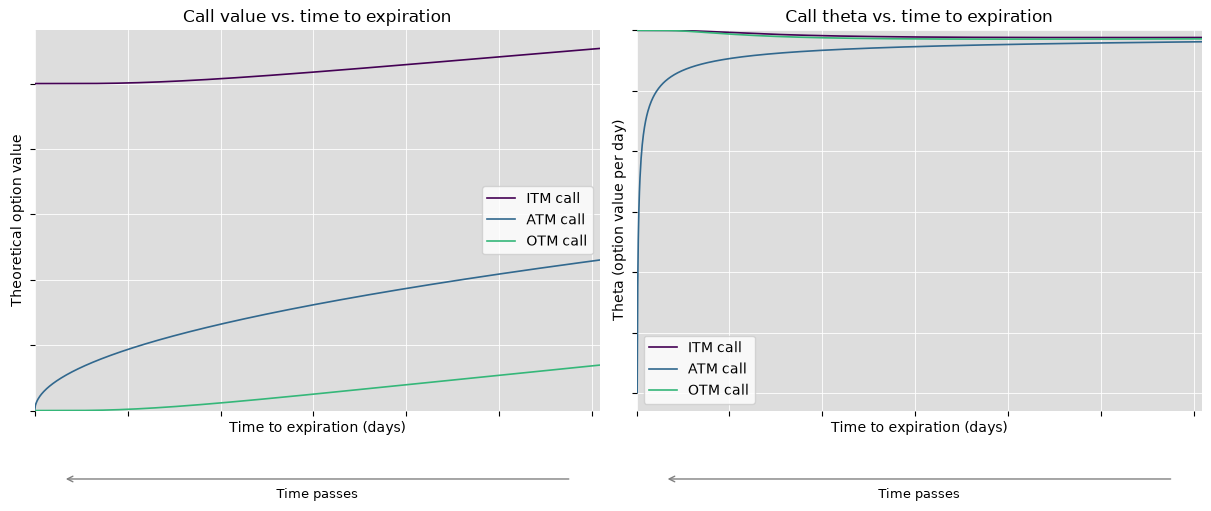

In [7]:
# Fixed spot and zero rates/dividends isolate the effect of time to expiry.
time_spot = 100
time_strikes = [90, 100, 110]
time_labels = ["ITM call", "ATM call", "OTM call"]
time_colors = ["#440154", "#31688e", "#35b779"]
time_volatility = 0.20
time_days = np.linspace(0, 365 / 3, 1001)
time_tau = time_days[1:] / 365

value_fig, (value_ax, theta_ax) = plt.subplots(
    1, 2, sharex=True, figsize=(12, 5), layout="constrained"
)
for strike, label, color in zip(time_strikes, time_labels, time_colors):
    d1 = (np.log(time_spot / strike) + 0.5 * time_volatility**2 * time_tau) / (
        time_volatility * np.sqrt(time_tau)
    )
    d2 = d1 - time_volatility * np.sqrt(time_tau)
    call_values = time_spot * norm.cdf(d1) - strike * norm.cdf(d2)
    # At expiration, the call is worth its intrinsic value.
    call_values = np.r_[max(time_spot - strike, 0), call_values]
    value_ax.plot(time_days, call_values, color=color, linewidth=1.2, label=label)
    # Calendar-time theta per day; ATM theta is undefined at expiry itself.
    theta_per_day = (
        -time_spot * norm.pdf(d1) * time_volatility / (2 * np.sqrt(time_tau)) / 365
    )
    theta_ax.plot(time_days[1:], theta_per_day, color=color, linewidth=1.2, label=label)

value_ax.set(
    title="Call value vs. time to expiration",
    xlabel="Time to expiration (days)",
    ylabel="Theoretical option value",
    xlim=(0, 365 / 3),
    ylim=(0, None),
)
theta_ax.set(
    title="Call theta vs. time to expiration",
    ylabel="Theta (option value per day)",
    ylim=(None, 0),
)
for ax in (value_ax, theta_ax):
    ax.set(xlabel="Time to expiration (days)", xlim=(0, 365 / 3))
    ax.set_facecolor("#dddddd")
    ax.set_axisbelow(True)
    ax.grid(color="white", linewidth=0.6)
    ax.legend()
    ax.tick_params(axis="both", labelbottom=False, labelleft=False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.annotate(
        "",
        xy=(0.05, -0.18),
        xytext=(0.95, -0.18),
        xycoords="axes fraction",
        arrowprops={"arrowstyle": "->", "color": "grey", "lw": 1},
        annotation_clip=False,
    )
    ax.text(0.5, -0.23, "Time passes", transform=ax.transAxes, ha="center", fontsize=9)
plt.show()

## Theta and Volatility

If the underlying is more volatile, the option holds more extrinsic value, and so ITM/OTM options will have greater theta. Interestingly for ATM options theta and volatility are directly proportional. 

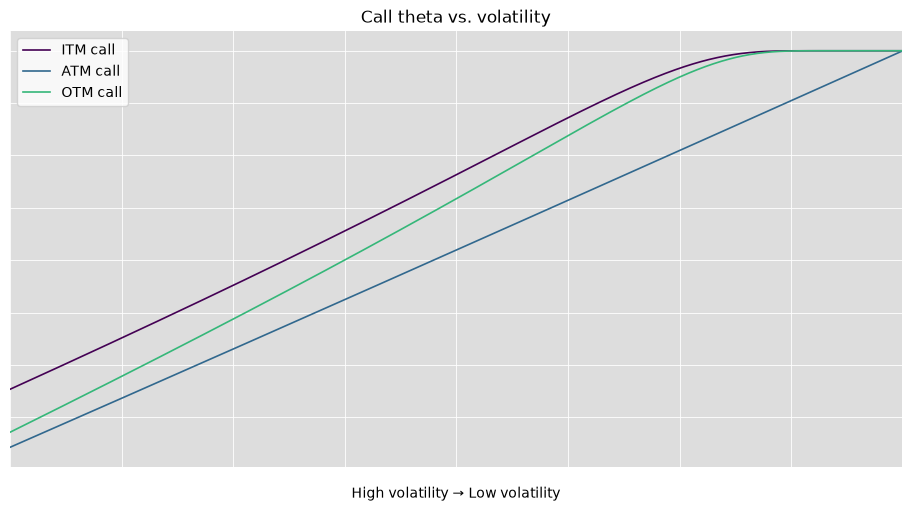

In [8]:
# Hold spot, strikes and time fixed; vary volatility from high to low.
# Zero interest rates and dividends isolate volatility's effect on theta.
theta_vol_spot = 100
theta_vol_tau = 30 / 365
theta_vol_grid = np.linspace(0.80, 0.001, 1001)
theta_vol_strikes = [90, 100, 110]
theta_vol_labels = ["ITM call", "ATM call", "OTM call"]
theta_vol_colors = ["#440154", "#31688e", "#35b779"]

theta_vol_fig, theta_vol_ax = plt.subplots(figsize=(9, 5), layout="constrained")
for strike, label, color in zip(theta_vol_strikes, theta_vol_labels, theta_vol_colors):
    d1 = (np.log(theta_vol_spot / strike) + 0.5 * theta_vol_grid**2 * theta_vol_tau) / (
        theta_vol_grid * np.sqrt(theta_vol_tau)
    )
    theta_values = (
        -theta_vol_spot
        * norm.pdf(d1)
        * theta_vol_grid
        / (2 * np.sqrt(theta_vol_tau))
        / 365
    )
    theta_vol_ax.plot(
        theta_vol_grid, theta_values, label=label, color=color, linewidth=1.2
    )

theta_vol_ax.set(
    title="Call theta vs. volatility",
    xlim=(theta_vol_grid[0], theta_vol_grid[-1]),
)
theta_vol_ax.set_facecolor("#dddddd")
theta_vol_ax.set_axisbelow(True)
theta_vol_ax.grid(color="white", linewidth=0.6)
theta_vol_ax.tick_params(axis="both", length=0, labelbottom=False, labelleft=False)
for spine in theta_vol_ax.spines.values():
    spine.set_visible(False)
theta_vol_ax.legend()
theta_vol_ax.text(
    0.5,
    -0.07,
    "High volatility → Low volatility",
    transform=theta_vol_ax.transAxes,
    ha="center",
)
plt.show()

## Vega

Generally, the higher the underlying price, the greater the vega. Moreover, the vega of an at-the-money option is proportional to its strike. The previous Greek, vanna ($\partial\Delta/\partial\sigma$), can also be expressed as $\partial\text{Vega}/\partial S$; these are mathematically identical by equality of mixed partial derivatives.

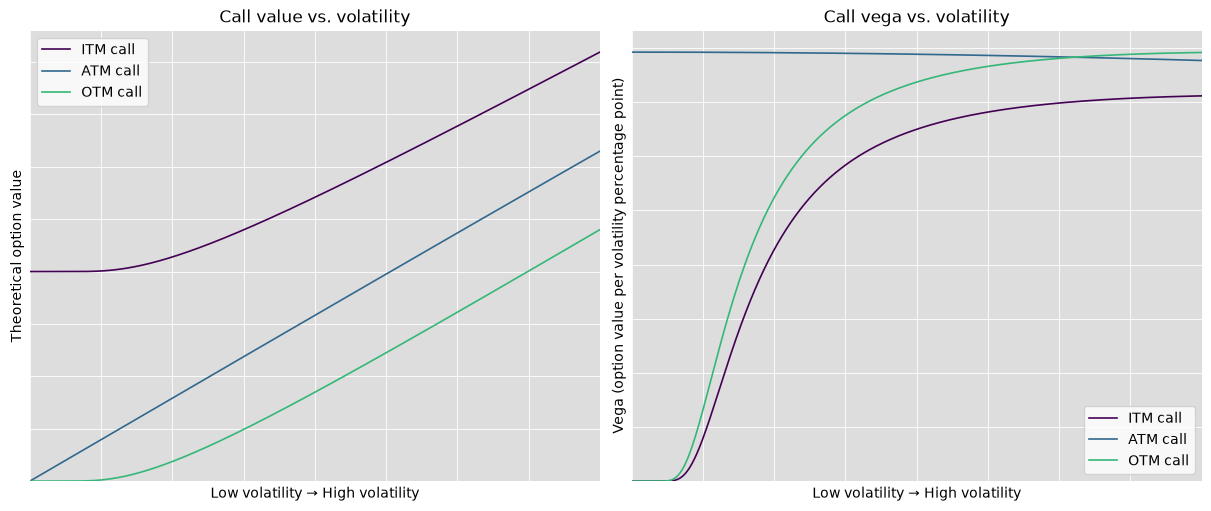

In [9]:
# Hold spot, strikes and time fixed with zero interest rates and dividends.
vega_spot = 100
vega_tau = 90 / 365
vega_volatilities = np.linspace(0.001, 0.80, 1001)
vega_strikes = [90, 100, 110]
vega_labels = ["ITM call", "ATM call", "OTM call"]
vega_colors = ["#440154", "#31688e", "#35b779"]

vega_fig, (vol_value_ax, vega_ax) = plt.subplots(
    1, 2, sharex=True, figsize=(12, 5), layout="constrained"
)
for strike, label, color in zip(vega_strikes, vega_labels, vega_colors):
    d1 = (np.log(vega_spot / strike) + 0.5 * vega_volatilities**2 * vega_tau) / (
        vega_volatilities * np.sqrt(vega_tau)
    )
    d2 = d1 - vega_volatilities * np.sqrt(vega_tau)
    values = vega_spot * norm.cdf(d1) - strike * norm.cdf(d2)
    vol_value_ax.plot(
        vega_volatilities, values, color=color, linewidth=1.2, label=label
    )

    # Vega per one percentage point increase in annualised volatility.
    vega_values = vega_spot * norm.pdf(d1) * np.sqrt(vega_tau) / 100
    vega_ax.plot(
        vega_volatilities, vega_values, color=color, linewidth=1.2, label=label
    )

vol_value_ax.set(
    title="Call value vs. volatility",
    xlabel="Low volatility → High volatility",
    ylabel="Theoretical option value",
    xlim=(0, vega_volatilities[-1]),
    ylim=(0, None),
)
vega_ax.set(
    title="Call vega vs. volatility",
    ylabel="Vega (option value per volatility percentage point)",
    ylim=(0, None),
)
for ax in (vol_value_ax, vega_ax):
    ax.set(xlabel="Low volatility → High volatility", xlim=(0, vega_volatilities[-1]))
    ax.set_facecolor("#dddddd")
    ax.set_axisbelow(True)
    ax.grid(color="white", linewidth=0.6)
    ax.tick_params(axis="both", length=0, labelbottom=False, labelleft=False)
    ax.legend()
    for spine in ax.spines.values():
        spine.set_visible(False)
plt.show()

Most notably, for ATM options the theoretical value increases linearly with volatility. From this we gather the vega (slope) is positive w.r.t volatility for atm options, for ITM/OTM it increases to a constant value from 0. The sensitivity of vega wrt volatility is referred to as volga. Notably the vega for ATM options actually declines slightly for high volatility, which is an important quirk to discuss later.

Below we plot the sensitivity of an option's price to volatility as time passes. Intuitively, options with greater time to expiry benefit from large volatility for price movements to realise, so we expect vega to decreases as we approach expiry. The derivative of vega w.r.t time to expiry is known as vega decay, and is greatest around 10 and 90 deltas.

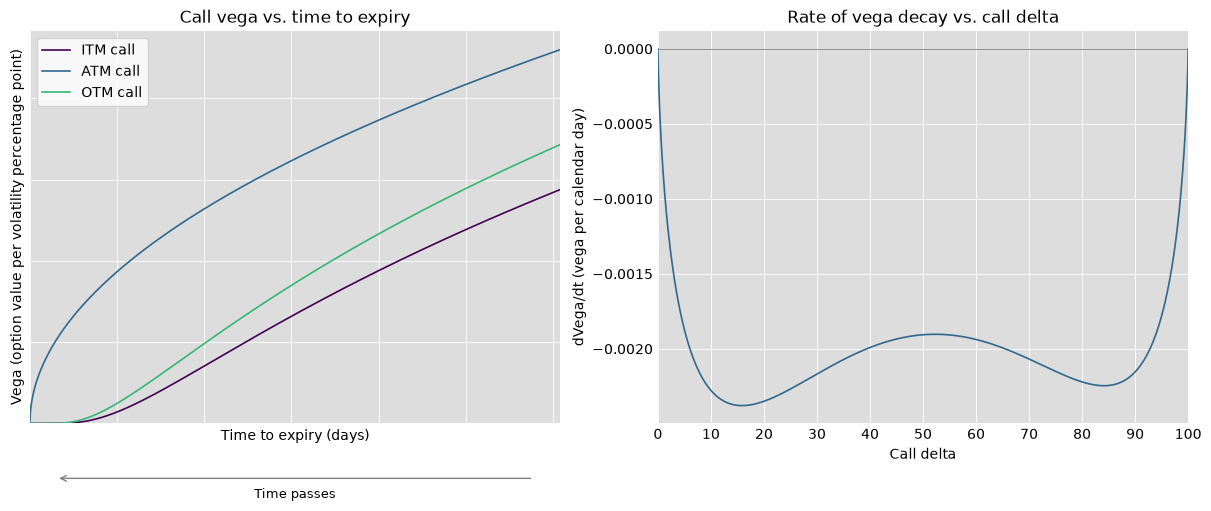

In [10]:
# Fixed spot, strikes and annualised volatility; zero rates and dividends.
vega_time_spot = 100
vega_time_sigma = 0.20
vega_time_days = np.linspace(0, 365 / 3, 1001)
vega_time_tau = vega_time_days[1:] / 365
vega_time_strikes = [90, 100, 110]
vega_time_labels = ["ITM call", "ATM call", "OTM call"]
vega_time_colors = ["#440154", "#31688e", "#35b779"]

vega_time_fig, (vega_time_ax, vega_delta_ax) = plt.subplots(
    1, 2, figsize=(12, 5), layout="constrained"
)
for strike, label, color in zip(vega_time_strikes, vega_time_labels, vega_time_colors):
    d1 = (
        np.log(vega_time_spot / strike) + 0.5 * vega_time_sigma**2 * vega_time_tau
    ) / (vega_time_sigma * np.sqrt(vega_time_tau))
    # Vega per one percentage point of volatility; zero at expiration.
    values = vega_time_spot * norm.pdf(d1) * np.sqrt(vega_time_tau) / 100
    vega_time_ax.plot(
        vega_time_days, np.r_[0, values], color=color, linewidth=1.2, label=label
    )

vega_time_ax.set(
    title="Call vega vs. time to expiry",
    xlabel="Time to expiry (days)",
    ylabel="Vega (option value per volatility percentage point)",
    xlim=(0, vega_time_days[-1]),
    ylim=(0, None),
)
vega_time_ax.set_facecolor("#dddddd")
vega_time_ax.set_axisbelow(True)
vega_time_ax.grid(color="white", linewidth=0.6)
vega_time_ax.tick_params(axis="both", length=0, labelbottom=False, labelleft=False)
vega_time_ax.legend()
for spine in vega_time_ax.spines.values():
    spine.set_visible(False)
vega_time_ax.annotate(
    "",
    xy=(0.05, -0.14),
    xytext=(0.95, -0.14),
    xycoords="axes fraction",
    arrowprops={"arrowstyle": "->", "color": "grey", "lw": 1},
    annotation_clip=False,
)
vega_time_ax.text(
    0.5, -0.19, "Time passes", transform=vega_time_ax.transAxes, ha="center", fontsize=9
)
# Snapshot across call deltas at 30 days to expiry.
# At each delta, differentiate at fixed spot, strike and annualised volatility.
# Calendar time t increases as time remaining T decreases: d/dt = -d/dT.
vega_decay_tau = 30 / 365
vega_delta_grid = np.linspace(0.000001, 0.999999, 1001)
vega_delta_d1 = norm.ppf(vega_delta_grid)
vega_delta_d2 = vega_delta_d1 - vega_time_sigma * np.sqrt(vega_decay_tau)
vega_snapshot = vega_time_spot * norm.pdf(vega_delta_d1) * np.sqrt(vega_decay_tau) / 100
# Vega is quoted per volatility percentage point; decay is per calendar day.
vega_decay = (
    -vega_snapshot * (1 + vega_delta_d1 * vega_delta_d2) / (2 * vega_decay_tau) / 365
)
vega_delta_ax.plot(
    np.r_[0, 100 * vega_delta_grid, 100],
    np.r_[0, vega_decay, 0],
    color="#31688e",
    linewidth=1.2,
)
vega_delta_ax.set(
    title="Rate of vega decay vs. call delta",
    xlabel="Call delta",
    ylabel="dVega/dt (vega per calendar day)",
    xlim=(0, 100),
    xticks=np.arange(0, 101, 10),
)
vega_delta_ax.set_facecolor("#dddddd")
vega_delta_ax.set_axisbelow(True)
vega_delta_ax.grid(color="white", linewidth=0.6)
vega_delta_ax.axhline(0, color="grey", linewidth=0.6)
vega_delta_ax.tick_params(axis="both", length=0, labelbottom=True, labelleft=True)
for spine in vega_delta_ax.spines.values():
    spine.set_visible(False)
plt.show()

## Gamma

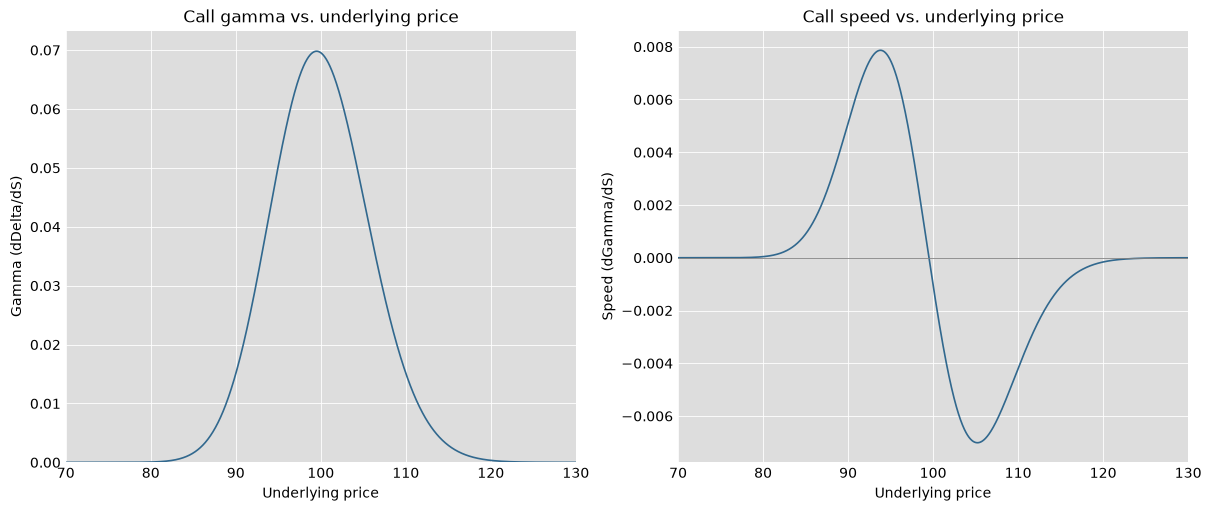

In [11]:
# Vary underlying price with fixed strike and volatility, at 30 days to expiry.
# Interest rates and dividends are zero.
gamma_strike = 100
gamma_spots = np.linspace(70, 130, 2001)
gamma_sigma = 0.20
gamma_expiry_days = [30]
gamma_expiry_colors = ["#31688e"]

gamma_speed_fig, (gamma_ax, speed_ax) = plt.subplots(
    1, 2, sharex=True, figsize=(12, 5), layout="constrained"
)
for days, color in zip(gamma_expiry_days, gamma_expiry_colors):
    gamma_tau = days / 365
    gamma_d1 = (
        np.log(gamma_spots / gamma_strike) + 0.5 * gamma_sigma**2 * gamma_tau
    ) / (gamma_sigma * np.sqrt(gamma_tau))
    gamma_values = norm.pdf(gamma_d1) / (gamma_spots * gamma_sigma * np.sqrt(gamma_tau))
    # Speed is the slope of gamma with respect to underlying price.
    speed_values = (
        -gamma_values
        / gamma_spots
        * (1 + gamma_d1 / (gamma_sigma * np.sqrt(gamma_tau)))
    )
    gamma_ax.plot(
        gamma_spots, gamma_values, color=color, linewidth=1.2, label=f"{days} days"
    )
    speed_ax.plot(
        gamma_spots, speed_values, color=color, linewidth=1.2, label=f"{days} days"
    )
gamma_ax.set(
    title="Call gamma vs. underlying price", ylabel="Gamma (dDelta/dS)", ylim=(0, None)
)
speed_ax.set(title="Call speed vs. underlying price", ylabel="Speed (dGamma/dS)")
speed_ax.axhline(0, color="grey", linewidth=0.6)
for ax in (gamma_ax, speed_ax):
    ax.set(xlabel="Underlying price", xlim=(gamma_spots[0], gamma_spots[-1]))
    ax.set_facecolor("#dddddd")
    ax.set_axisbelow(True)
    ax.grid(color="white", linewidth=0.6)
    ax.tick_params(axis="both", length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
plt.show()

Gamma is greatest at the money and increases as time passes (or volatility decreases), conversely gamma decreases as volatility increases (delta becomes flatter and closer to 50 across the board) or time to expiry increases. 

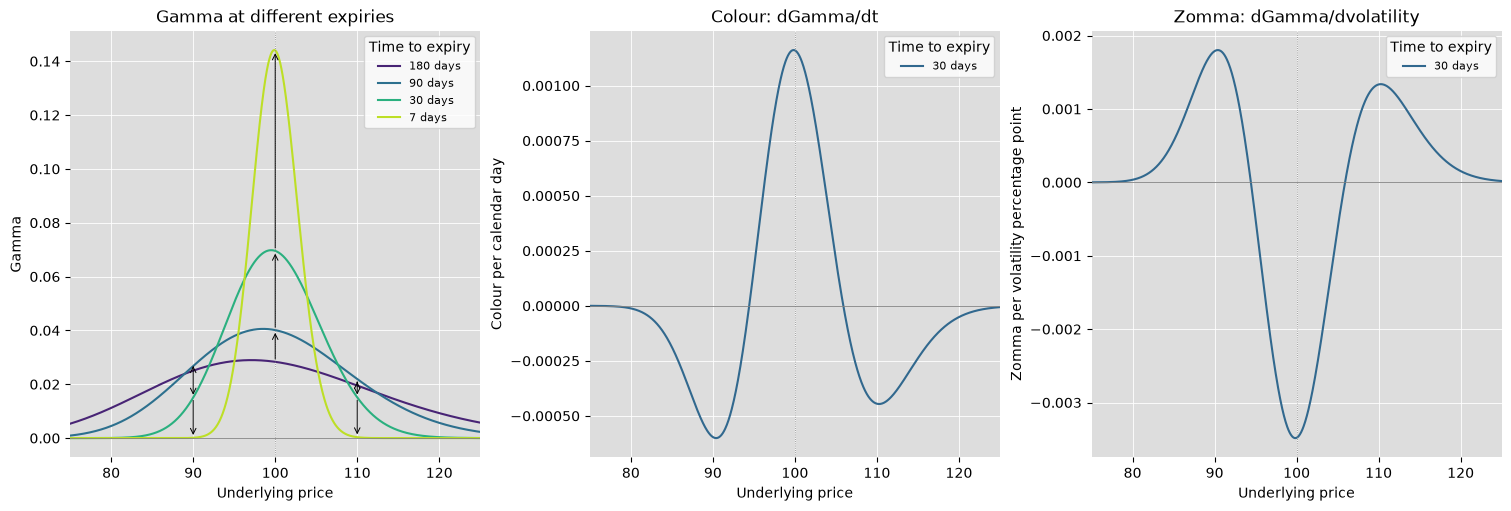

In [12]:
# Gamma across expiries, with colour and zomma shown at one representative expiry.
greek_spots = np.linspace(75, 125, 1001)
greek_strike = 100
greek_sigma = 0.20
greek_expiries = [180, 90, 30, 7]
greek_colours = plt.get_cmap("viridis")(np.linspace(0.1, 0.9, len(greek_expiries)))
representative_days = 30
representative_tau = representative_days / 365

greek_fig, (gamma_time_ax, colour_ax, zomma_ax) = plt.subplots(
    1, 3, figsize=(15, 5), layout="constrained"
)
for days, colour in zip(greek_expiries, greek_colours):
    tau = days / 365
    d1 = (np.log(greek_spots / greek_strike) + 0.5 * greek_sigma**2 * tau) / (
        greek_sigma * np.sqrt(tau)
    )
    gamma = norm.pdf(d1) / (greek_spots * greek_sigma * np.sqrt(tau))
    gamma_time_ax.plot(greek_spots, gamma, color=colour, label=f"{days} days")

representative_d1 = (
    np.log(greek_spots / greek_strike) + 0.5 * greek_sigma**2 * representative_tau
) / (greek_sigma * np.sqrt(representative_tau))
representative_d2 = representative_d1 - greek_sigma * np.sqrt(representative_tau)
representative_gamma = norm.pdf(representative_d1) / (
    greek_spots * greek_sigma * np.sqrt(representative_tau)
)
representative_colour = (
    representative_gamma
    * (1 - representative_d1 * representative_d2)
    / (2 * representative_tau)
    / 365
)
representative_zomma = (
    representative_gamma
    * (representative_d1 * representative_d2 - 1)
    / greek_sigma
    / 100
)
colour_ax.plot(
    greek_spots,
    representative_colour,
    color="#31688e",
    label=f"{representative_days} days",
)
zomma_ax.plot(
    greek_spots,
    representative_zomma,
    color="#31688e",
    label=f"{representative_days} days",
)

gamma_time_ax.set_title("Gamma at different expiries")
colour_ax.set_title("Colour: dGamma/dt")
zomma_ax.set_title("Zomma: dGamma/dvolatility")
gamma_time_ax.set_ylabel("Gamma")
colour_ax.set_ylabel("Colour per calendar day")
zomma_ax.set_ylabel("Zomma per volatility percentage point")
for ax in (gamma_time_ax, colour_ax, zomma_ax):
    ax.set(xlabel="Underlying price", xlim=(greek_spots[0], greek_spots[-1]))
    ax.set_facecolor("#dddddd")
    ax.set_axisbelow(True)
    ax.grid(color="white", linewidth=0.6)
    ax.axvline(greek_strike, color="grey", linestyle=":", linewidth=0.6)
    ax.axhline(0, color="grey", linewidth=0.6)
    ax.legend(title="Time to expiry", fontsize=8)
    for spine in ax.spines.values():
        spine.set_visible(False)


# Arrows show the direction from longer expiry to shorter expiry on gamma.
def gamma_at(price, days):
    tau = days / 365
    d1 = (np.log(price / greek_strike) + 0.5 * greek_sigma**2 * tau) / (
        greek_sigma * np.sqrt(tau)
    )
    return norm.pdf(d1) / (price * greek_sigma * np.sqrt(tau))


for price in (90, 100, 110):
    for start, end in zip(greek_expiries[:-1], greek_expiries[1:]):
        gamma_time_ax.annotate(
            "",
            xy=(price, gamma_at(price, end)),
            xytext=(price, gamma_at(price, start)),
            arrowprops={"arrowstyle": "->", "color": "black", "lw": 0.7},
        )
plt.show()

As gamma is greatest ATM and gamme of an ATM increases as expiry approaches/volatility decreases, experienced traders recognise that close to expiry options are among the riskiest to trade. 

## Lambda

Lambda measures the percentage change in an option's price for a one percent change in the underlying price:

Sometimes we are interested in percentage changes in option contract prices, as opposed to absolute changes. For example, if an option is worth 4 units, with the underlying at 100 and a delta of 20%. Then the underlying moving to 101 (a 1% increase) means the option is approximately worth 4.20 units, a 5% increase. 

$$
\Lambda = \frac{\text{change in option price} / \text{option price}}{\text{change in stock price} / \text{stock price}}
= \frac{\Delta \times \text{stock price}}{\text{option price}}
$$

For example, if delta is 20, the stock price is 100, and the option price is 4:

$$
\Lambda = \frac{0.2 \times 100}{4} = 5
$$

Lambda is greatest for options far out of the money because they are relatively cheap and benefit most, in percentage terms, from movements that increase their delta. Increasing volatility generally lowers lambda for calls and puts; decreasing volatility, or the passage of time, has the opposite effect.